In [734]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

<font size="5">Read the data and verify if it returns rows</font>

In [735]:
df_mark_campaign = pd.read_csv("marketing_data.csv")

In [736]:
df_mark_campaign.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


In [737]:
df_mark_campaign.shape

(2240, 28)

In [738]:
#Read all column
df_mark_campaign.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', ' Income ',
       'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines',
       'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Response', 'Complain', 'Country'],
      dtype='object')

In [739]:
#Remove whitespace in income column name
df_mark_campaign.rename(columns={' Income ':'Income'},inplace = True)

<font size="5">Verify that Dt_Customer and Income are imported correctly.</font>

In [740]:
df_mark_campaign['Dt_Customer'] = pd.to_datetime(df_mark_campaign['Dt_Customer'])
df_mark_campaign['Dt_Customer']

0      2014-06-16
1      2014-06-15
2      2014-05-13
3      2014-05-11
4      2014-04-08
          ...    
2235   2013-03-07
2236   2013-01-22
2237   2012-12-03
2238   2012-11-29
2239   2012-09-01
Name: Dt_Customer, Length: 2240, dtype: datetime64[ns]

In [741]:
#Convert income into a number for easy calculations
df_mark_campaign['Income'] = df_mark_campaign['Income'].str.replace('$','').str.replace(',','').astype('float')
df_mark_campaign['Income']

0       84835.0
1       57091.0
2       67267.0
3       32474.0
4       21474.0
         ...   
2235    66476.0
2236    31056.0
2237    46310.0
2238    65819.0
2239    94871.0
Name: Income, Length: 2240, dtype: float64

In [742]:
#Count no of null values in Income column
income_null_count = df_mark_campaign['Income'].isnull().sum()
income_null_count

np.int64(24)

<font size="5">To perform imputation in the income column, verify education and marital status columns data</font>

In [743]:
df_mark_campaign['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
YOLO          2
Absurd        2
Name: count, dtype: int64

In [744]:
# We can replace Alone, YOLO, Absurd with single as they are in fewer counts and also come in a category of single
df_mark_campaign['Marital_Status'] = df_mark_campaign['Marital_Status'].apply(lambda x:'Single' if str(x) in ['Alone','YOLO','Absurd'] else str(x))
df_mark_campaign['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      487
Divorced    232
Widow        77
Name: count, dtype: int64

In [745]:
df_mark_campaign['Education'].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [746]:
# 2N Cycle can be replaced by Masters
df_mark_campaign['Education']=df_mark_campaign['Education'].apply(lambda x:'Master' if x=='2n Cycle' else str(x))
df_mark_campaign['Education'].value_counts()

Education
Graduation    1127
Master         573
PhD            486
Basic           54
Name: count, dtype: int64

In [747]:
df_income_null = df_mark_campaign.loc[df_mark_campaign['Income'].isna(),['Education','Marital_Status']]
df_income_null


,Education,Marital_Status
134,PhD,Married
262,Graduation,Married
394,PhD,Together
449,Graduation,Single
525,PhD,Married
590,Master,Married
899,Master,Together
997,Graduation,Single
1096,Master,Single
1185,Master,Together


In [748]:
df1 = df_mark_campaign[["Education", 'Marital_Status','Income']].groupby(["Education", "Marital_Status"]).sum().reset_index()
df1

,Education,Marital_Status,Income
0,Basic,Divorced,9548.0
1,Basic,Married,439210.0
2,Basic,Single,328296.0
3,Basic,Together,297361.0
4,Basic,Widow,22123.0
5,Graduation,Divorced,6488599.0
6,Graduation,Married,21793311.0
7,Graduation,Single,12738677.0
8,Graduation,Together,15891167.0
9,Graduation,Widow,1924183.0


In [749]:
unique_Education = pd.unique(df_mark_campaign.Education)
unique_MStatus=pd.unique(df_mark_campaign.Marital_Status)
df_temp = df_mark_campaign.copy()
for e in unique_Education:
    for m in unique_MStatus:
        condition = (df_temp.Education == e) & (df_temp.Marital_Status == m)
        temp_data = df_temp[condition]
        mean = np.round(np.mean(temp_data['Income']),3)
        temp_data['Income'] = temp_data['Income'].fillna(mean)
        print(f"Missing Value in 'Income' column is replaced with {mean} where Education:{e} and Marital Status: {m}")
        df_temp[condition]=temp_data
df_mark_campaign=df_temp.copy()


Missing Value in 'Income' column is replaced with 54526.042 where Education:Graduation and Marital Status: Divorced
Missing Value in 'Income' column is replaced with 51365.633 where Education:Graduation and Marital Status: Single
Missing Value in 'Income' column is replaced with 50800.259 where Education:Graduation and Marital Status: Married
Missing Value in 'Income' column is replaced with 55758.481 where Education:Graduation and Marital Status: Together
Missing Value in 'Income' column is replaced with 54976.657 where Education:Graduation and Marital Status: Widow
Missing Value in 'Income' column is replaced with 53096.615 where Education:PhD and Marital Status: Divorced
Missing Value in 'Income' column is replaced with 53039.667 where Education:PhD and Marital Status: Single
Missing Value in 'Income' column is replaced with 58138.032 where Education:PhD and Marital Status: Married
Missing Value in 'Income' column is replaced with 56041.422 where Education:PhD and Marital Status: To

<font size="5">Create variables to populate the total number of children, age, and total spending.</font>

In [750]:
df_mark_campaign['Total_No_Of_Child'] = df_mark_campaign['Kidhome'] + df_mark_campaign['Teenhome']
df_mark_campaign['Age'] =pd.Timestamp.now().year - df_mark_campaign['Year_Birth']
df_mark_campaign['Total_Spending']=df_mark_campaign[['MntWines','MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts']].sum(axis=1)
df_mark_campaign[['Total_No_Of_Child','Age','Total_Spending']]

,Total_No_Of_Child,Age,Total_Spending
0,0,55,972
1,0,64,540
2,1,67,221
3,2,58,11
4,1,36,57
...,...,...,...
2235,1,49,611
2236,1,48,39
2237,1,49,295
2238,0,47,1320


<font size="5">Box plots and histograms to understand the distributions and outliers.</font>

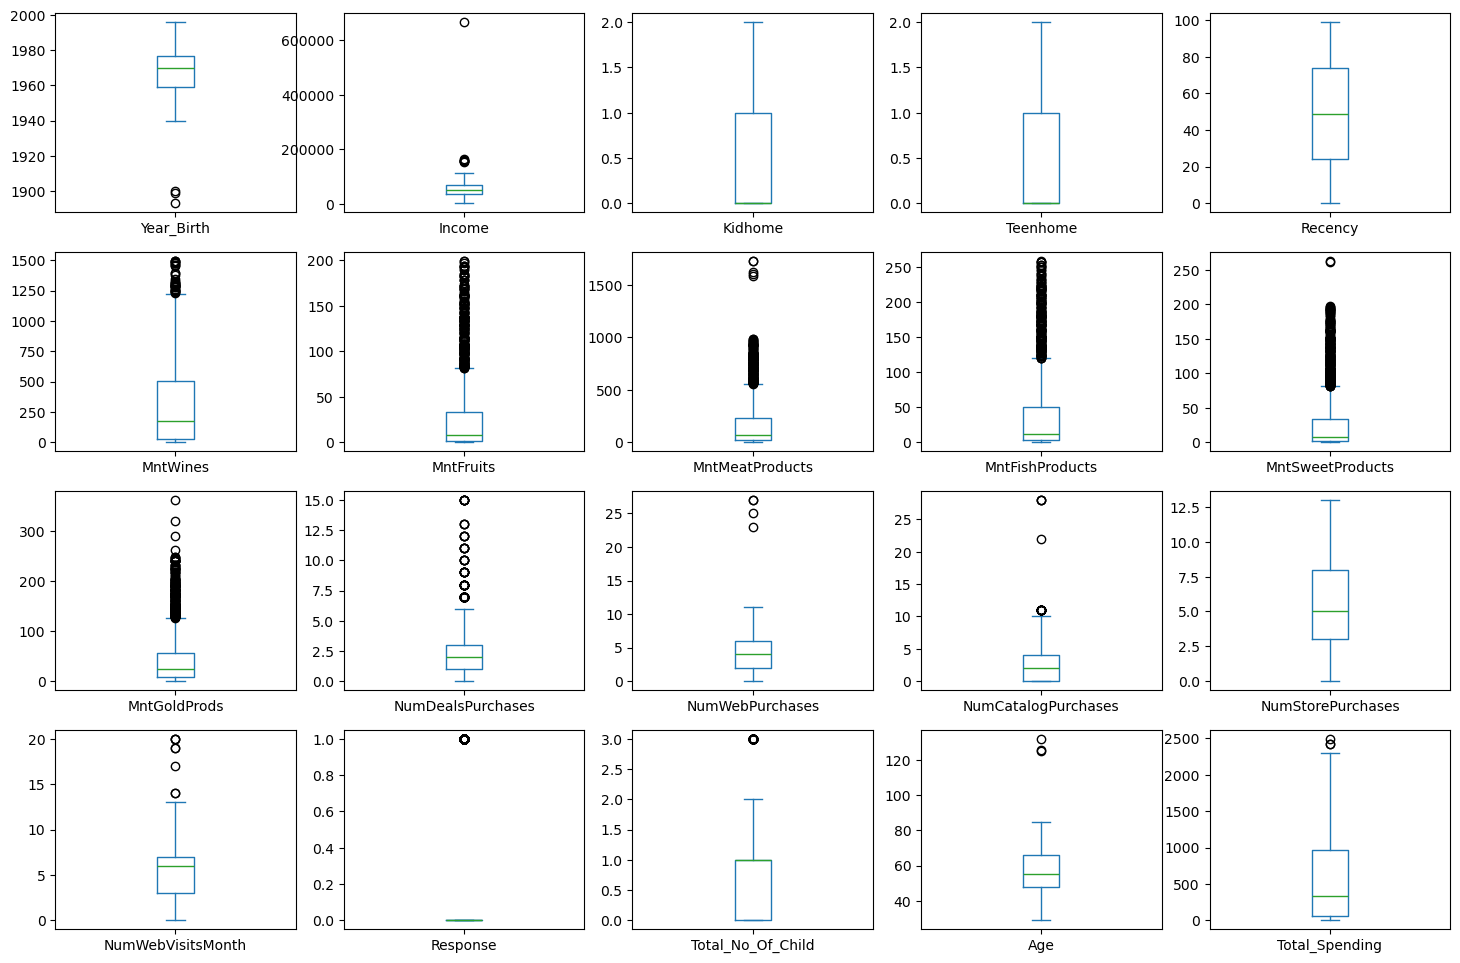

In [751]:
import matplotlib.pyplot as plt

#Drop few columns as plotting is not required for them
df_box_plot = df_mark_campaign.drop(['ID','AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1','AcceptedCmp2', 'Complain'],axis=1)
numeric_cols = df_box_plot.select_dtypes(include=['number']).columns
df_mark_campaign[numeric_cols].plot(subplots=True, layout=(5,5), kind='box', figsize=(18,15))
plt.show()

<Axes: >

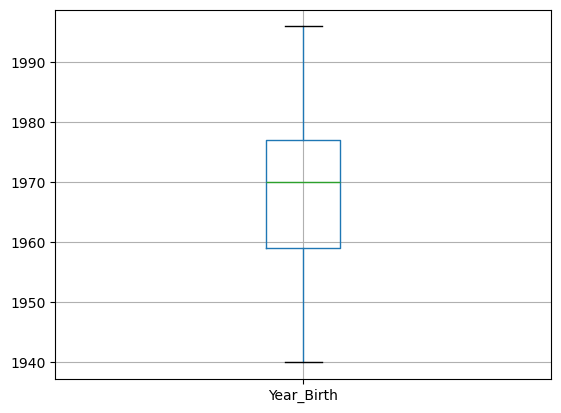

In [752]:
#Remove outliesrs in Year_Birth
df_mark_campaign = df_mark_campaign.drop(df_mark_campaign[df_mark_campaign['Year_Birth'] <= 1900].index)
df_mark_campaign.boxplot('Year_Birth')

<Axes: >

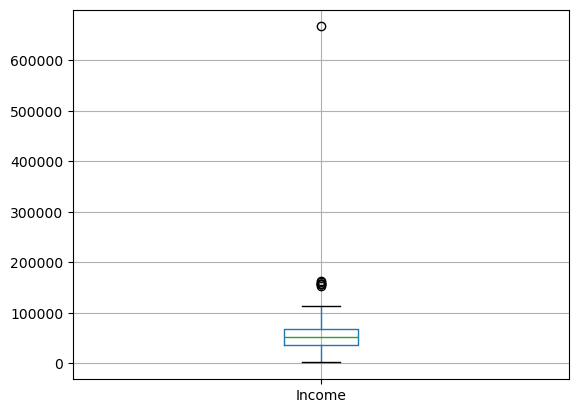

In [753]:
df_mark_campaign.boxplot('Income')

<Axes: >

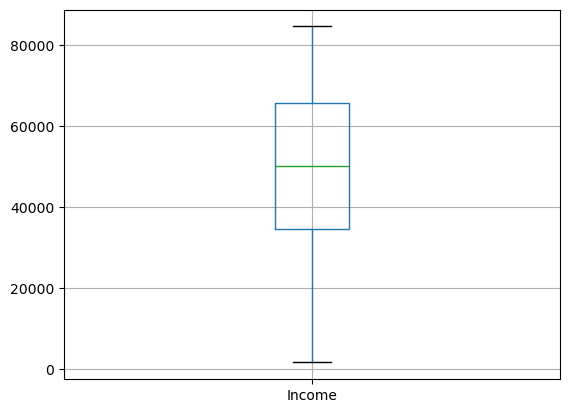

In [754]:
#Remove outliers in Income column
q1=df_mark_campaign['Income'].quantile(0.25)
q2=df_mark_campaign['Income'].quantile(0.75)

q=q2-q1
lower_bound = q1 - 1.5*q
upper_bound = q1 + 1.5*q

df_mark_campaign = df_mark_campaign[(df_mark_campaign['Income'] >= lower_bound) & (df_mark_campaign['Income'] <= upper_bound)]
df_mark_campaign.boxplot('Income')

<Axes: xlabel='Income', ylabel='Density'>

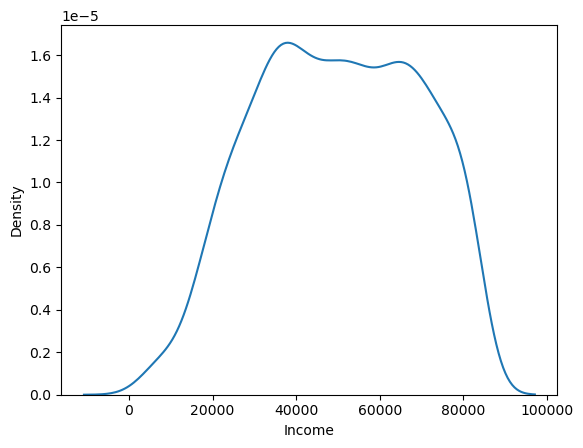

In [755]:
# Distribution of Income
import seaborn as sns
sns.kdeplot(data=df_mark_campaign, x="Income")

<font size=5>Use ordinal encoding and one hot encoding according to different types of categorical variables.</font>

In [756]:
#As age,totalkids are there drop Year_Birth,Kidhome,Teenhome columns. 
df_mark_campaign = df_mark_campaign.drop(['Year_Birth','Kidhome','Teenhome'],axis=1)

In [757]:
# Ordinal encoding for 'Education'
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories=[df_mark_campaign.Education.unique().tolist()])
df_mark_campaign['Education1']=encoder.fit_transform(df_mark_campaign[['Education']])

# for categorical variables use OneHotEncoder
df_mark_campaign = pd.get_dummies(df_mark_campaign, columns=[ "Marital_Status"])
df_mark_campaign.head(5)

,ID,Education,Income,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Country,Total_No_Of_Child,Age,Total_Spending,Education1,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
1,1,Graduation,57091.0,2014-06-15,0,464,5,64,7,0,...,CA,0,64,540,0.0,False,False,True,False,False
2,10476,Graduation,67267.0,2014-05-13,0,134,11,59,15,2,...,US,1,67,221,0.0,False,True,False,False,False
3,1386,Graduation,32474.0,2014-05-11,0,10,0,1,0,0,...,AUS,2,58,11,0.0,False,False,False,True,False
4,5371,Graduation,21474.0,2014-04-08,0,6,16,24,11,0,...,SP,1,36,57,0.0,False,False,True,False,False
5,7348,PhD,71691.0,2014-03-17,0,336,130,411,240,32,...,SP,0,67,1149,1.0,False,False,True,False,False


<font size=5>Create a heatmap to showcase the correlation between different pairs of variables.</font>

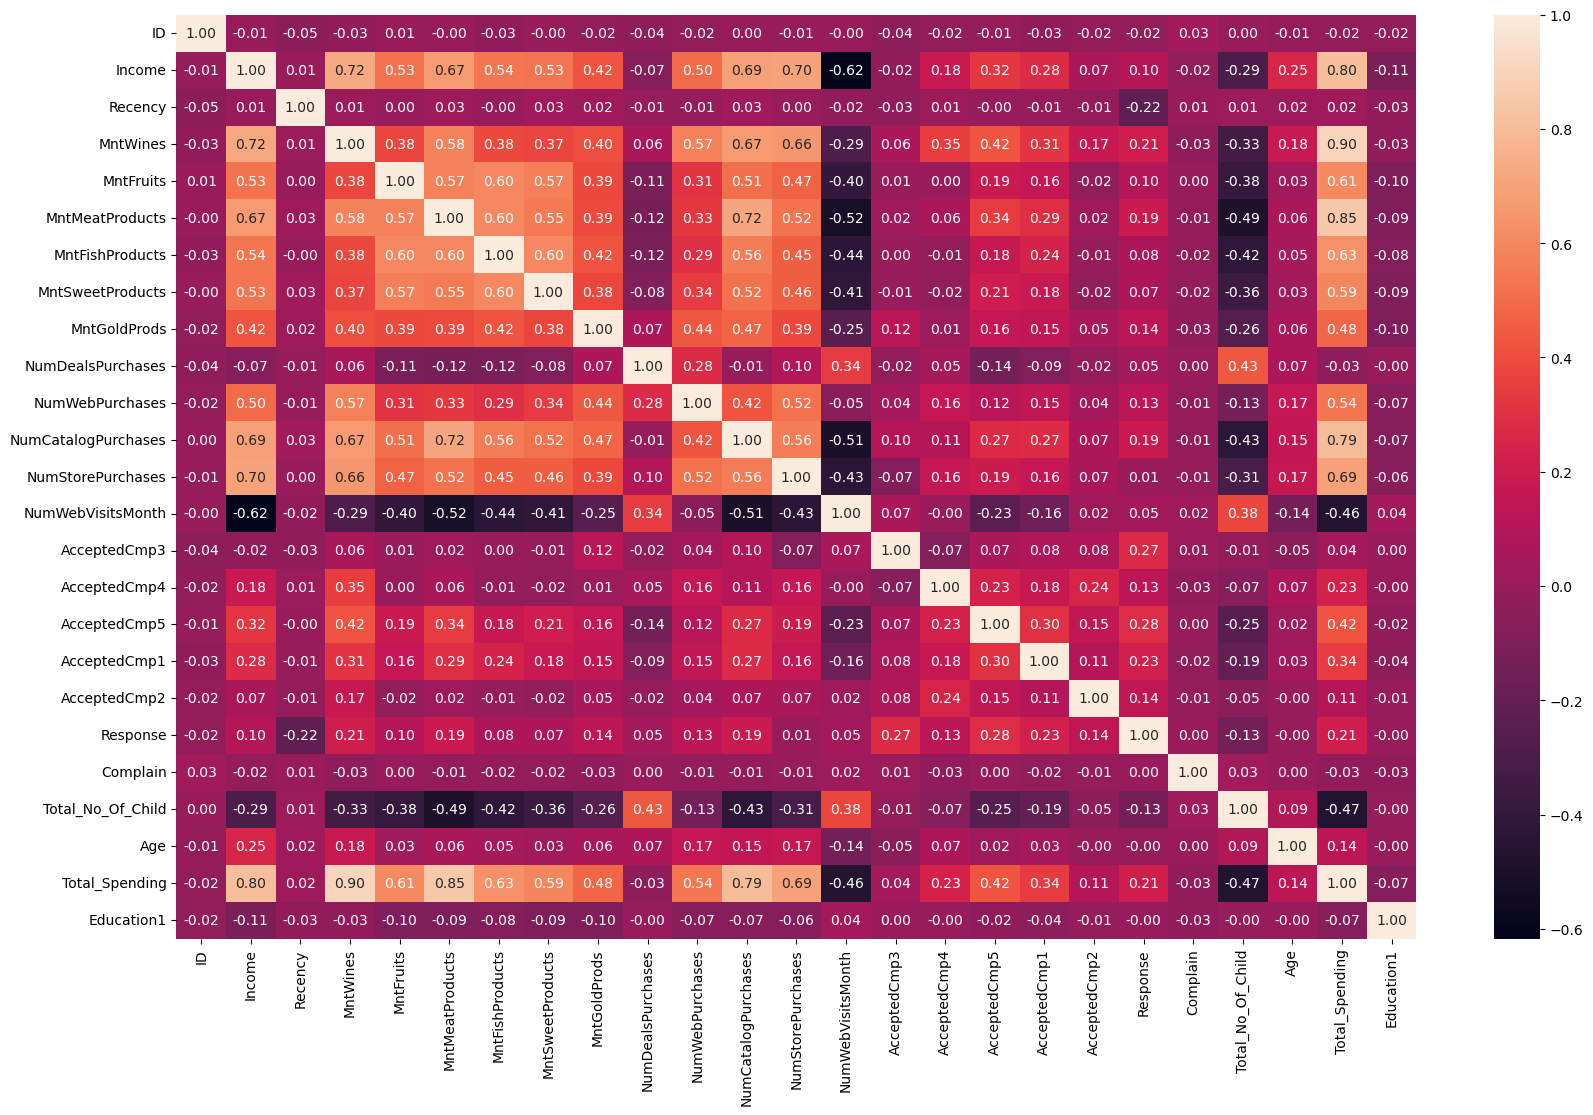

In [758]:
numeric_df = df_mark_campaign.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()
plt.figure(figsize=(20,12))
sns.heatmap(corr_matrix,annot=True,fmt=".2f")
plt.show()

In [759]:
# lets check the highest correlation 
numeric_df = df_mark_campaign.select_dtypes(include=['number'])
numeric_df.corr()['Response'].sort_values(ascending=False)

Response               1.000000
AcceptedCmp5           0.280116
AcceptedCmp3           0.270046
AcceptedCmp1           0.229167
Total_Spending         0.214724
MntWines               0.210965
NumCatalogPurchases    0.190682
MntMeatProducts        0.187248
AcceptedCmp2           0.142294
MntGoldProds           0.138005
NumWebPurchases        0.132406
AcceptedCmp4           0.132062
Income                 0.101566
MntFruits              0.099532
MntFishProducts        0.075349
MntSweetProducts       0.074870
NumDealsPurchases      0.045828
NumWebVisitsMonth      0.045042
NumStorePurchases      0.007486
Complain               0.004721
Education1            -0.000406
Age                   -0.003474
ID                    -0.022038
Total_No_Of_Child     -0.132066
Recency               -0.215108
Name: Response, dtype: float64

<font size=5>Test the following hypothesis</font>

<font size=5>1. Older people are not as tech-savvy and probably prefer shopping in-store.</font>

In [760]:
df_age=df_mark_campaign[['Age','NumWebPurchases','NumStorePurchases']]


df_age.loc[(df_age['Age'] <= 25) , 'Age_Group'] = 'Young'
df_age.loc[(df_age['Age']  > 50) , 'Age_Group'] = 'Elderly'
df_age.loc[(df_age['Age']  > 25) & (df_age['Age'] <= 50) , 'Age_Group'] = 'Middle Age'
df_age.head(10)

,Age,NumWebPurchases,NumStorePurchases,Age_Group
1,64,7,7,Elderly
2,67,3,5,Elderly
3,58,1,2,Elderly
4,36,3,2,Middle Age
5,67,4,5,Elderly
6,71,10,7,Elderly
7,58,2,3,Elderly
8,71,6,9,Elderly
9,71,6,9,Elderly
10,78,5,10,Elderly


In [761]:
df_age['Age_Group'].value_counts()

Age_Group
Elderly       1402
Middle Age     733
Name: count, dtype: int64

In [762]:
df_age_plot=df_age[["Age_Group", 'NumWebPurchases','NumStorePurchases']].groupby(["Age_Group"]).sum()  
df_age_plot

,NumWebPurchases,NumStorePurchases
Age_Group,,
Elderly,6029,8379
Middle Age,2588,3813


<Axes: xlabel='Age_Group'>

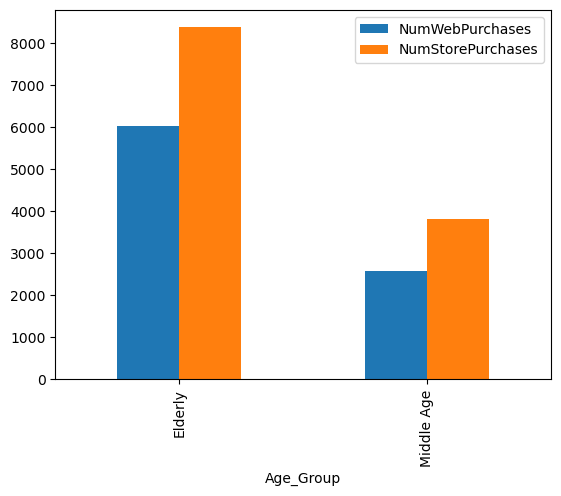

In [763]:
df_age_plot.plot.bar()

<font size=3>From the bar plot we can see that elderly people have more store purchases than middle age people.>/font>

<font size=5> 2. Customers with kids probably have less time to visit a store and would prefer to shop online.</font>

In [764]:
df_kids=df_mark_campaign[['Total_No_Of_Child', 'NumWebPurchases','NumStorePurchases']].groupby(['Total_No_Of_Child']).sum()
df_kids

,NumWebPurchases,NumStorePurchases
Total_No_Of_Child,,
0,2344,3938
1,4780,6251
2,1344,1800
3,149,203


<Axes: xlabel='Total_No_Of_Child'>

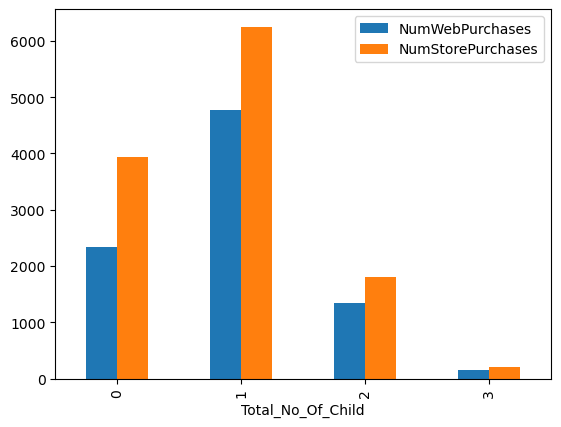

In [765]:
df_kids.plot.bar()

<font size=3>We can see that customers with more than 1 child are spending less and also prefer store purchases but compared to other parents who have less kids these parents shop online more.<font>

<font size=5>3. Other distribution channels may cannibalize sales at the store.</font>

([<matplotlib.patches.Wedge at 0x1a4fca31450>,
 [Text(0.9585271272511255, 0.5396533575580761, 'Deals'),
  Text(-0.34879959004379746, 1.0432347990674387, 'Online'),
  Text(-1.0872015016650483, -0.1673107730460419, 'Catalog'),
  Text(0.3697426477451704, -1.0359972849570558, 'Instore')])

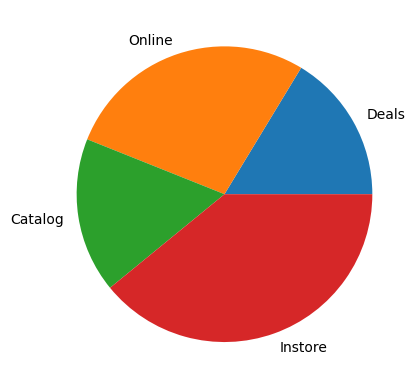

In [766]:
labels = ['Deals','Online','Catalog','Instore']
sizes = [df_mark_campaign.NumDealsPurchases.sum(),
         df_mark_campaign.NumWebPurchases.sum(),
         df_mark_campaign.NumCatalogPurchases.sum(),
         df_mark_campaign.NumStorePurchases.sum()]

fig, ax = plt.subplots()
ax.pie(sizes, labels=labels)

<font size=2>Sales are highest at Store than Catalog,Deals and Online channels.</font>

<font size=5>4. Does the US fare significantly better than the rest of the world in terms of total purchases?</font>

In [767]:
totalPurchases = df_mark_campaign[['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'Country']]
totalPurchases.head()

,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Country
1,1,7,3,7,CA
2,1,3,2,5,US
3,1,1,0,2,AUS
4,2,3,1,2,SP
5,1,4,7,5,SP


In [768]:
totalPurchases['Total_Purchases']=totalPurchases['NumDealsPurchases']+totalPurchases['NumWebPurchases']+totalPurchases['NumCatalogPurchases']+totalPurchases['NumStorePurchases']
totalPurchases.head()

,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Country,Total_Purchases
1,1,7,3,7,CA,18
2,1,3,2,5,US,11
3,1,1,0,2,AUS,4
4,2,3,1,2,SP,8
5,1,4,7,5,SP,17


In [769]:
avg_purchases_per_country = totalPurchases.groupby('Country').agg(Total_Purchases = ('Total_Purchases','sum'))
avg_purchases_per_country.head()

,Total_Purchases
Country,
AUS,2219
CA,3740
GER,1709
IND,1976
ME,59


In [770]:
avg_purchases_per_country['Total_Customers'] = totalPurchases['Country'].value_counts()
avg_purchases_per_country

,Total_Purchases,Total_Customers
Country,,
AUS,2219,155
CA,3740,250
GER,1709,117
IND,1976,142
ME,59,3
SA,4832,323
SP,14976,1039
US,1680,106


In [771]:
avg_purchases_per_country['Purchases_Per_Customer'] = np.floor(avg_purchases_per_country['Total_Purchases']/avg_purchases_per_country['Total_Customers'])	
avg_purchases_per_country

,Total_Purchases,Total_Customers,Purchases_Per_Customer
Country,,,
AUS,2219,155,14.0
CA,3740,250,14.0
GER,1709,117,14.0
IND,1976,142,13.0
ME,59,3,19.0
SA,4832,323,14.0
SP,14976,1039,14.0
US,1680,106,15.0


In [772]:
avg_purchases_per_country
avg_purchases_per_country.assign(country = avg_purchases_per_country.index.get_level_values('Country'))
avg_purchases_per_country.reset_index(inplace = True)
avg_purchases_per_country.head()                                                                                                     

,Country,Total_Purchases,Total_Customers,Purchases_Per_Customer
0,AUS,2219,155,14.0
1,CA,3740,250,14.0
2,GER,1709,117,14.0
3,IND,1976,142,13.0
4,ME,59,3,19.0


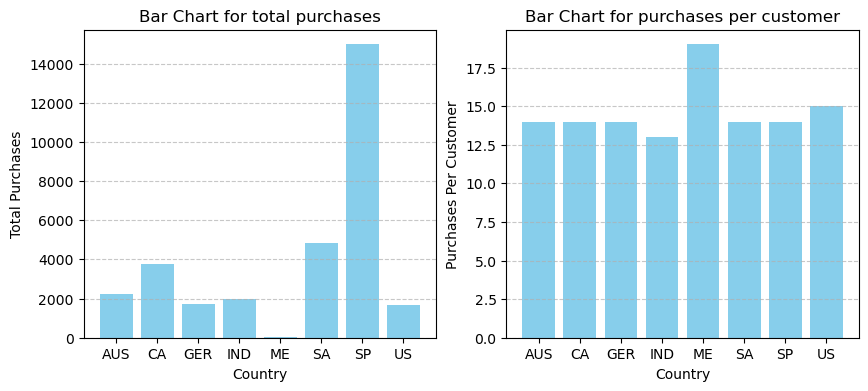

In [773]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4)) 
# First bar chart
axes[0].bar(avg_purchases_per_country['Country'], avg_purchases_per_country['Total_Purchases'], color='skyblue')
axes[0].set_title('Bar Chart for total purchases')
axes[0].set_xlabel('Country')
axes[0].set_ylabel('Total Purchases')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Second bar chart
axes[1].bar(avg_purchases_per_country['Country'], avg_purchases_per_country['Purchases_Per_Customer'], color='skyblue')
axes[1].set_title('Bar Chart for purchases per customer')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Purchases Per Customer')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

<font size=3>Total no of purchases are more in Spain but US stands in 2nd position in terms of purchases per customer.So US fares better than rest of the world.</fonr>

<font size=5>Use appropriate visualization to help analyze the following<font>

<font size=5>1. Which products are performing the best, and which are performing the least in terms of revenue?</font>

In [774]:
df_mark_campaign.columns


Index(['ID', 'Education', 'Income', 'Dt_Customer', 'Recency', 'MntWines',
       'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Response', 'Complain', 'Country', 'Total_No_Of_Child',
       'Age', 'Total_Spending', 'Education1', 'Marital_Status_Divorced',
       'Marital_Status_Married', 'Marital_Status_Single',
       'Marital_Status_Together', 'Marital_Status_Widow'],
      dtype='object')

([<matplotlib.patches.Wedge at 0x1a4f92bc550>,
 [Text(-0.027591541508953488, 1.0996539032064405, 'Wines'),
  Text(-1.080670975315977, -0.2053052437460267, 'Fruits'),
  Text(-0.44409919378060414, -1.0063676793714202, 'Meat'),
  Text(0.6319548827098592, -0.9003516125487688, 'Fish'),
  Text(0.8943250136454646, -0.6404551272087997, 'Sweet'),
  Text(1.0682320449583356, -0.2624505632002581, 'Gold')])

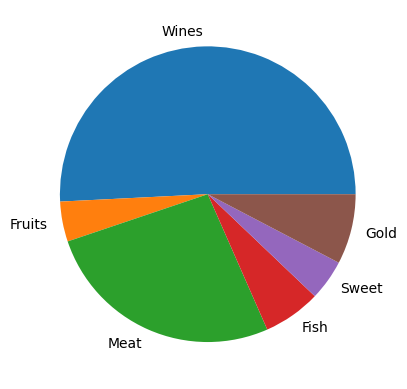

In [775]:
labels = ['Wines','Fruits','Meat','Fish','Sweet','Gold']
sizes = [df_mark_campaign.MntWines.sum(),
         df_mark_campaign.MntFruits.sum(),
         df_mark_campaign.MntMeatProducts.sum(),
         df_mark_campaign.MntFishProducts.sum(),
         df_mark_campaign.MntSweetProducts.sum(),
         df_mark_campaign.MntGoldProds.sum()]

fig, ax = plt.subplots()
ax.pie(sizes, labels=labels)

<font size=3>According to pie chart Wines are sold more than any other products so wines is performing best. Then next performing product is meat. The least performing products are Fruits and Sweet.</font>

<font size=5>2. Is there any pattern between the age of customers and the last campaign acceptance rate?</font>

In [776]:
# Read csv file again as we have dropped campaign acceptance columns for analysis
df_mark_campaign1 = pd.read_csv('marketing_data.csv')

In [777]:
df_mark_campaign1.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', ' Income ',
       'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines',
       'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Response', 'Complain', 'Country'],
      dtype='object')

In [778]:
df_mark_campaign1['Age'] =pd.Timestamp.now().year - df_mark_campaign1['Year_Birth']
df_age1=df_mark_campaign1[['Age','AcceptedCmp1','AcceptedCmp2','AcceptedCmp3','AcceptedCmp4','AcceptedCmp5']]


df_age1.loc[(df_age1['Age'] <= 25) , 'Age_Group'] = 'Young'
df_age1.loc[(df_age1['Age']  > 50) , 'Age_Group'] = 'Elderly'
df_age1.loc[(df_age1['Age']  > 25) & (df_age1['Age'] <= 50) , 'Age_Group'] = 'Middle Age'
df_age1.head(10)

,Age,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Age_Group
0,55,0,0,0,0,0,Elderly
1,64,0,1,0,0,0,Elderly
2,67,0,0,0,0,0,Elderly
3,58,0,0,0,0,0,Elderly
4,36,0,0,1,0,0,Middle Age
5,67,0,0,0,0,0,Elderly
6,71,0,0,1,0,0,Elderly
7,58,0,0,0,0,0,Elderly
8,71,0,0,0,0,0,Elderly
9,71,0,0,0,0,0,Elderly


In [779]:
df_age1['Age_Group'].value_counts()

Age_Group
Elderly       1462
Middle Age     778
Name: count, dtype: int64

In [780]:
df_age1[['AcceptedCmp1','AcceptedCmp2','AcceptedCmp3','AcceptedCmp4']].groupby(df_age1['Age_Group']).sum()

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4
Age_Group,,,,
Elderly,88,23,89,129
Middle Age,56,7,74,38


<font size=3>Elderly people are twice in number than middle age people. We can see the pattern between them that Middle age are accepting campaign is in descending order and Elderly people campaign accepting is in ascending order.So middle age people accepted the campaigns faster than the Elderly people. </font>


<font size=5>3. Which Country has the greatest number of customers who accepted the last campaign?</font>

In [781]:
df_last_campaign = df_mark_campaign1['AcceptedCmp4'].groupby(df_mark_campaign1['Country']).sum().sort_values(ascending=False)
df_last_campaign

Country
SP     89
CA     24
SA     20
GER    11
IND    11
AUS     6
US      6
ME      0
Name: AcceptedCmp4, dtype: int64

<Axes: xlabel='Country'>

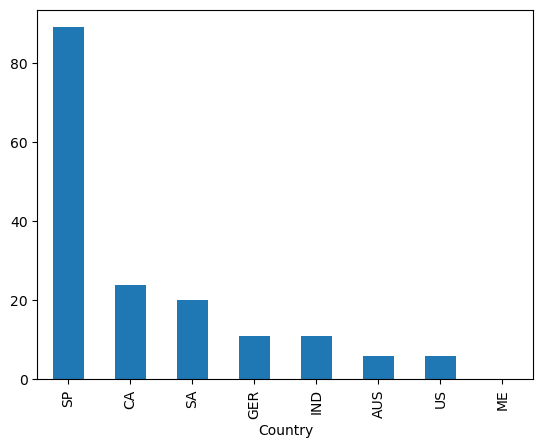

In [782]:
df_last_campaign.plot.bar()

<font size=3>Spain has greatest number of customers who accepted the last campaign<font>

<font size=5>4. Do you see any pattern in the no. of children at home and total spend?<font>

In [783]:
df_mark_campaign_copy = df_mark_campaign1
df_mark_campaign_copy['Total_Spending']=df_mark_campaign_copy[['MntWines','MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts']].sum(axis=1)
df_total_spending = df_mark_campaign_copy[['Total_Spending']].groupby(df_mark_campaign_copy['Kidhome']).sum()
df_total_spending

,Total_Spending
Kidhome,
0,1087702
1,164541
2,6136


<Axes: xlabel='Kidhome'>

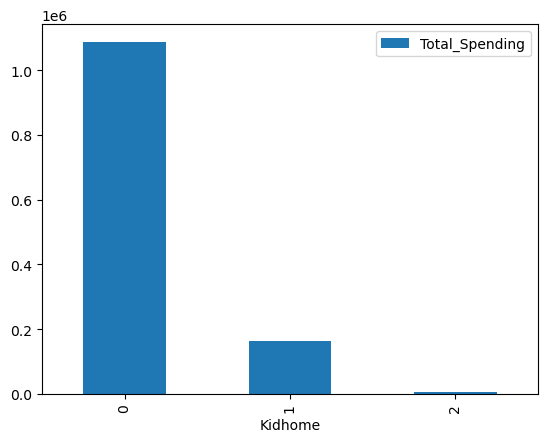

In [784]:
df_total_spending.plot.bar()

<font size=3>The pattern between no of kids at home and total spending is that people with more kids spend less than that of with less kids or no kids<font>

<font size=5>5. Education background of the customers who complained in the last 2 years.<font>

In [785]:
df_mark_campaign1['Education']=df_mark_campaign['Education'].apply(lambda x:'Master' if x=='2n Cycle' else str(x))
df_education = df_mark_campaign1[df_mark_campaign1['Complain']==1]['Education']
df_education

206         Master
297         Master
355         Master
555     Graduation
662     Graduation
728     Graduation
775     Graduation
943            PhD
1000    Graduation
1087    Graduation
1103    Graduation
1298        Master
1336    Graduation
1475        Master
1506    Graduation
1744    Graduation
1866    Graduation
2081    Graduation
2082    Graduation
2091    Graduation
2233           NaN
Name: Education, dtype: object

<font size=3> The Education background of people who complained last 2 years is Graduation and Masters.<font>